# HuggingFace Diffusers 라이브러리 사용 가이드

이 노트북에서는 HuggingFace Diffusers 라이브러리를 사용하여 Stable Diffusion 모델을 활용하는 방법을 학습합니다.

## 주요 학습 내용
1. **Diffusers 라이브러리 기본 사용법**
2. **Stable Diffusion 파이프라인 설정**
3. **텍스트-이미지 생성**
4. **고급 설정 및 커스터마이징**

## 사전 요구사항
- Python 3.7+
- PyTorch
- CUDA 지원 GPU (권장)

## 라이브러리 설치
```bash
pip install diffusers accelerate transformers
```


# [Diffusers](https://huggingface.co/docs/diffusers/ko/index)
- Diffusers는 이미지, 오디오, 심지어 분자의 3D 구조를 생성하기 위한 최첨단 사전 훈련된 diffusion 모델을 위한 라이브러리입니다.
- 간단한 추론 솔루션을 찾고 있든, 자체 diffusion 모델을 훈련하고 싶든, Diffusers는 두 가지 모두를 지원하는 모듈식 툴박스입니다.

## [Diffusers 아키텍처](https://towardsdatascience.com/stable-diffusion-using-hugging-face-501d8dbdd8)

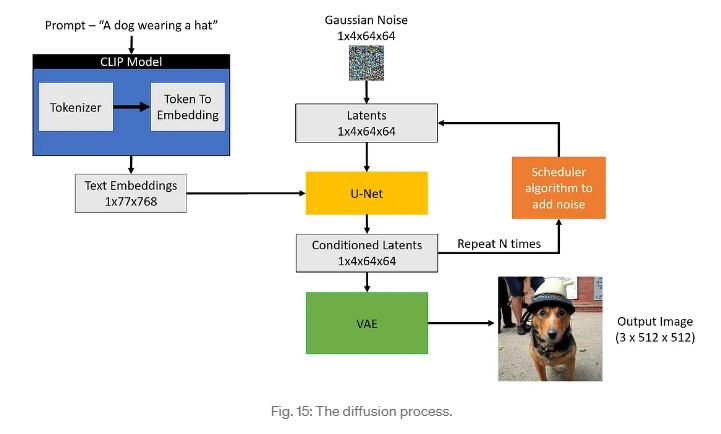

### CLIP Text Encoder
- CLIP(Contrastive Language–Image Pretraining)은 OpenAI에서 만든 모델로,
텍스트와 이미지 간의 의미를 연결하는 데 특화되어 있습니다.
- diffusers에서 사용되는 CLIP Text Encoder는 그중 텍스트 부분만 담당하며,
프롬프트를 입력받아 토큰 단위로 나눈 후 임베딩 벡터로 변환합니다.
- Stable Diffusion에서는 이 임베딩을 기반으로 UNet에 조건(Condition)으로 전달하여
이미지 생성을 제어합니다.

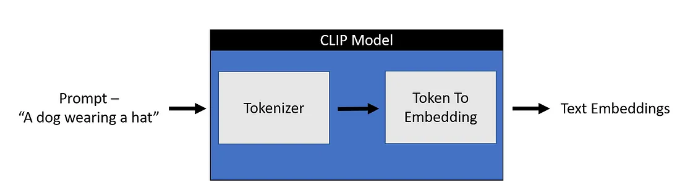

### U-Net model
- diffusers에서 U-Net은 Stable Diffusion 모델의 핵심으로, 노이즈가 섞인 이미지에서 점점 깨끗한 이미지를 복원해 나가는 역할을 합니다.
- U-Net은 "이미지를 그리는 화가"처럼 동작하며, CLIP Text Encoder가 전달한 **텍스트 의미(조건)**를 반영해 점점 원하는 이미지로 변환시킵니다.

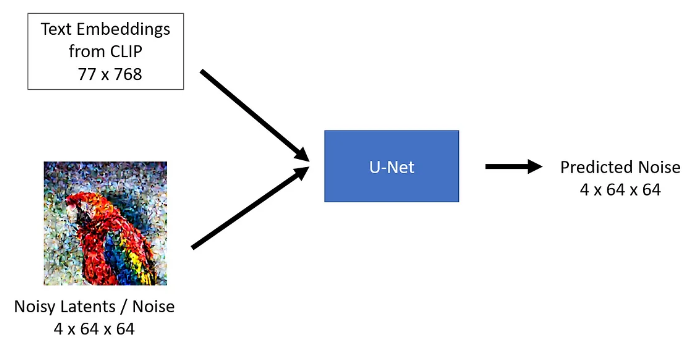

### Scheduler

```scss
입력(노이즈 이미지)
   ↓
[Encoder: 특징 추출, 해상도 점점 ↓]
   ↓
[중간 Bottleneck]
   ↓
[Decoder: 이미지 복원, 해상도 점점 ↑]
   ↓
출력(덜 노이즈 이미지)
```

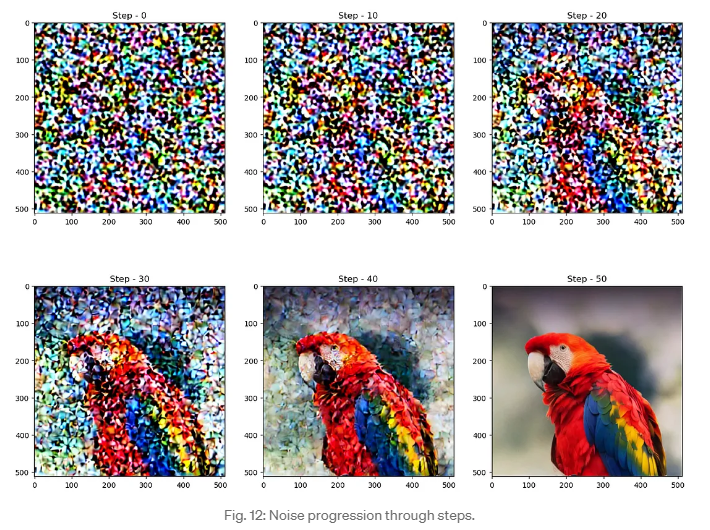

### VAE Decoder
- diffusers에서 VAE Decoder는 Stable Diffusion의 마지막 단계에서 잠재 공간(latent space)에 있는 데이터를 실제 이미지로 복원하는 역할을 합니다.
- 쉽게 말해:
    - `U-Net`: 64×64×4 크기의 추상적인 "그림의 밑그림"을 그린다.
    - `VAE Decoder`: 이 밑그림을 512×512×3 크기의 실제 이미지로 "채색"한다.

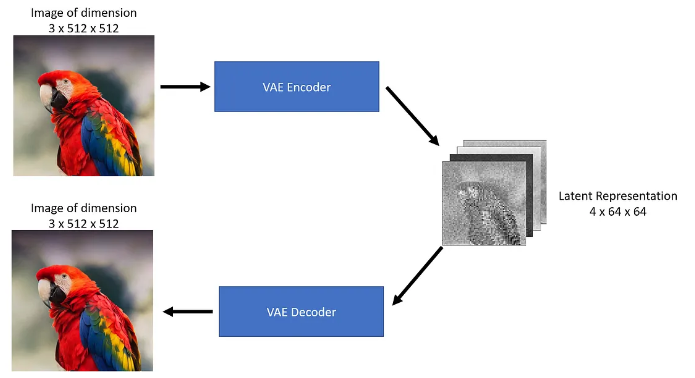

# Install

In [ ]:
!pip install --upgrade pip 
!pip install transformers==4.37.0 accelerate==0.27.0 huggingface_hub==0.20.3 diffusers==0.25.0 peft==0.7.0 typing_extensions==4.15.0

  Using cached torch-2.1.0-cp311-cp311-manylinux1_x86_64.whl.metadata (25 kB)
  Using cached transformers-4.37.0-py3-none-any.whl.metadata (129 kB)
  Using cached huggingface_hub-0.20.3-py3-none-any.whl.metadata (12 kB)
  Using cached typing_extensions-4.15.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_curand_cu12-10.3.2.106-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cusolver_cu12-11.4.5.107

## Restart Kernel 실행!
> 설치된 라이브러리가 적용되도록 Kernel 재실행

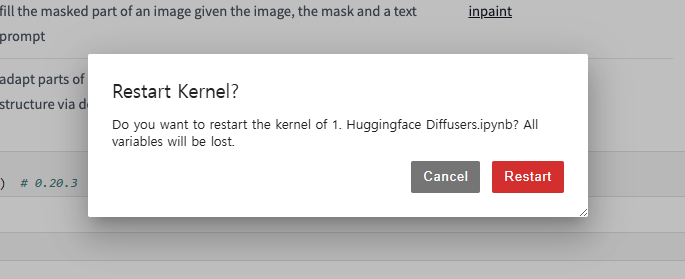

In [ ]:
import torch, transformers, diffusers, huggingface_hub
print(torch.__version__)
print(transformers.__version__)
print(diffusers.__version__)
print(huggingface_hub.__version__)
print(torch.cuda.is_available())

# [DiffusionPipeline](https://huggingface.co/docs/diffusers/main/en/api/pipelines/overview)
- DiffusionPipeline 은 추론을 위해 사전 학습된 diffusion 시스템을 사용하는 가장 쉬운 방법입니다.
- 모델과 스케줄러를 포함하는 엔드 투 엔드 시스템입니다. 다양한 작업에 DiffusionPipeline을 바로 사용할 수 있습니다.

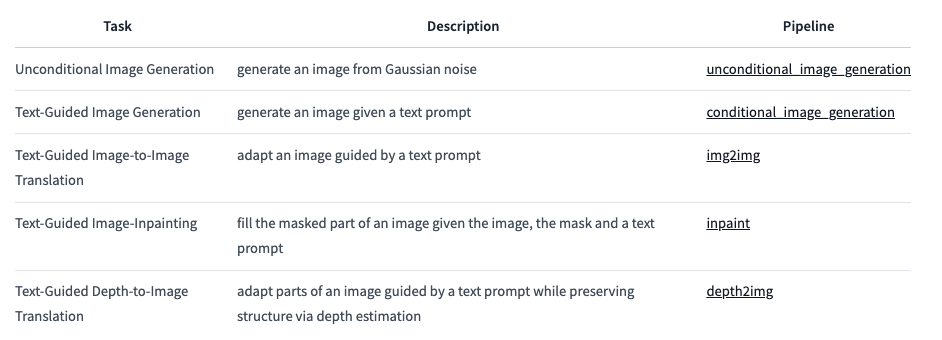

In [ ]:
from diffusers import DiffusionPipeline

pipeline = DiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5")

- The DiffusionPipeline은 모든 모델링, 토큰화, 스케줄링 컴포넌트를 다운로드하고 캐시합니다.
- Stable Diffusion Pipeline은 무엇보다도 UNet2DConditionModel과 PNDMScheduler로 구성되어 있음을 알 수 있습니다:

In [ ]:
pipeline

- 이 모델은 약 14억 개의 파라미터로 구성되어 있으므로 GPU에서 파이프라인을 실행할 것을 강력히 권장합니다. PyTorch에서와 마찬가지로 제너레이터 객체를 GPU로 이동할 수 있습니다:

In [ ]:
pipeline.to("cuda")

- 이제 파이프라인에 텍스트 프롬프트를 전달하여 이미지를 생성한 다음 노이즈가 제거된 이미지에 액세스할 수 있습니다. 기본적으로 이미지 출력은 PIL.Image 객체로 감싸집니다.

In [ ]:
image = pipeline("An image of a squirrel in Picasso style").images[0]
image

## Model
- 대부분의 모델은 노이즈가 있는 샘플을 가져와 각 시간 간격마다 노이즈가 적은 이미지와 입력 이미지 사이의 차이인 노이즈 잔차(다른 모델은 이전 샘플을 직접 예측하거나 속도 또는 v-prediction을 예측하는 학습을 합니다)을 예측합니다. 모델을 믹스 앤 매치하여 다른 diffusion 시스템을 만들 수 있습니다.
- 모델은 `from_pretrained()` 메서드로 시작되며, 이 메서드는 모델 가중치를 로컬에 캐시하여 다음에 모델을 로드할 때 더 빠르게 로드할 수 있습니다. 훑어보기에서는 고양이 이미지에 대해 학습된 체크포인트가 있는 기본적인 unconditional 이미지 생성 모델인 UNet2DModel을 로드합니다:

In [ ]:
from diffusers import UNet2DModel

repo_id = "google/ddpm-cat-256"
model = UNet2DModel.from_pretrained(repo_id)

모델 매개변수에 액세스하려면 model.config를 호출합니다:
- `sample_size`: 입력 샘플의 높이 및 너비 치수입니다.
- `in_channels`: 입력 샘플의 입력 채널 수입니다.
- `down_block_types 및 up_block_types`: UNet 아키텍처를 생성하는 데 사용되는 다운 및 업샘플링 블록의 유형.
- `block_out_channels`: 다운샘플링 블록의 출력 채널 수. 업샘플링 블록의 입력 채널 수에 역순으로 사용되기도 합니다.
- `layers_per_block`: 각 UNet 블록에 존재하는 ResNet 블록의 수입니다.

In [ ]:
model.config

- 추론에 모델을 사용하려면 랜덤 가우시안 노이즈로 이미지 모양을 만듭니다. 모델이 여러 개의 무작위 노이즈를 수신할 수 있으므로 ‘batch’ 축, 입력 채널 수에 해당하는 ‘channel’ 축, 이미지의 높이와 너비를 나타내는 ‘sample_size’ 축이 있어야 합니다:

In [ ]:
import torch

torch.manual_seed(0)

# 모델 설정에 따라 랜덤 노이즈 샘플 생성
# 모델의 입력 채널 수와 샘플 크기 정보를 사용하여 적절한 형태의 노이즈 텐서 생성
noisy_sample = torch.randn(1, model.config.in_channels, model.config.sample_size, model.config.sample_size)

# 생성된 노이즈 샘플의 형태(shape) 확인
# (배치 크기, 채널 수, 높이, 너비) 형태의 4차원 텐서
noisy_sample.shape

- 추론을 위해 모델에 노이즈가 있는 이미지와 timestep을 전달합니다. ‘timestep’은 입력 이미지의 노이즈 정도를 나타내며, 시작 부분에 더 많은 노이즈가 있고 끝 부분에 더 적은 노이즈가 있습니다.
- 이를 통해 모델이 diffusion 과정에서 시작 또는 끝에 더 가까운 위치를 결정할 수 있습니다. sample 메서드를 사용하여 모델 출력을 얻습니다:

In [ ]:
# 그래디언트 계산을 비활성화하여 메모리 사용량을 줄이고 추론 속도를 향상시킴
with torch.no_grad():
    # UNet 모델을 사용하여 주어진 노이즈 샘플과 타임스텝(2)에서 예상되는 노이즈 잔차를 예측
    # sample: 입력 노이즈 이미지, timestep: 현재 타임스텝, .sample: 예측된 노이즈 출력
    noisy_residual = model(sample=noisy_sample, timestep=2).sample

### DDPMScheduler 초기화

이제 DDPM(Denoising Diffusion Probabilistic Models) 스케줄러를 생성합니다.

**DDPMScheduler의 역할:**
- 노이즈 제거 과정을 단계별로 관리
- 각 타임스텝에서 노이즈 레벨을 조절
- 모델 출력을 바탕으로 다음 단계의 샘플 생성

**주요 매개변수:**
- `num_train_timesteps`: 훈련 시 사용된 타임스텝 수 (기본값: 1000)
- `beta_schedule`: 노이즈 스케줄 타입 ("linear", "scaled_linear" 등)
- `prediction_type`: 모델이 예측하는 값의 타입 ("epsilon", "sample" 등)


## Scheduler
- 실제 예를 생성하려면 노이즈 제거 프로세스를 안내할 스케줄러가 필요합니다.
- 스케줄러는 모델 출력이 주어졌을 때 노이즈가 많은 샘플에서 노이즈가 적은 샘플로 전환하는 것을 관리합니다.
- 가장 중요한 매개변수는 다음과 같습니다:
  - `num_train_timesteps`: 노이즈 제거 프로세스의 길이, 즉 랜덤 가우스 노이즈를 데이터 샘플로 처리하는 데 필요한 타임스텝 수입니다.
  - `beta_schedule`: 추론 및 학습에 사용할 노이즈 스케줄 유형입니다.
  - `beta_start 및 beta_end`: 노이즈 스케줄의 시작 및 종료 노이즈 값입니다.

### 노이즈 제거 단계 실행

스케줄러의 `step()` 메서드를 사용하여 한 번의 노이즈 제거 단계를 수행합니다.

**step() 메서드의 매개변수:**
- `model_output`: 모델이 예측한 노이즈 (residual)
- `timestep`: 현재 타임스텝 (높을수록 더 많은 노이즈)
- `sample`: 현재 노이즈가 포함된 샘플

**반환값:**
- `prev_sample`: 노이즈가 한 단계 제거된 샘플
- 이 과정을 반복하면 최종적으로 깨끗한 이미지가 생성됩니다


In [ ]:
from diffusers import DDPMScheduler

scheduler = DDPMScheduler.from_config(repo_id)
scheduler

### 이미지 후처리 및 표시 함수

생성된 텐서를 PIL 이미지로 변환하여 시각화하는 유틸리티 함수입니다.

**후처리 과정:**
1. **텐서 형태 변경**: `(batch, channel, height, width)` → `(batch, height, width, channel)`
2. **정규화 해제**: `[-1, 1]` 범위 → `[0, 255]` 범위로 변환
3. **데이터 타입 변환**: float → uint8 (이미지 픽셀 값)
4. **PIL 이미지 생성**: NumPy 배열을 PIL.Image 객체로 변환

**매개변수:**
- `sample`: 모델이 생성한 이미지 텐서
- `i`: 현재 단계 번호 (표시용)


In [ ]:
# 스케줄러를 사용하여 노이즈를 한 단계 제거하여 덜 노이즈가 많은 이미지 생성
# model_output: UNet이 예측한 노이즈 잔차, timestep: 현재 타임스텝, sample: 현재 노이즈 샘플
# .prev_sample: 스케줄러가 계산한 이전 단계의 덜 노이즈가 많은 샘플
less_noisy_sample = scheduler.step(model_output=noisy_residual, timestep=2, sample=noisy_sample).prev_sample

# 처리된 샘플의 형태(shape) 확인
# 원본과 동일한 차원을 유지하는지 검증
less_noisy_sample.shape

- less_noisy_sample을 다음 timestep으로 넘기면 노이즈가 더 줄어듭니다! 이제 이 모든 것을 한데 모아 전체 노이즈 제거 과정을 시각화해 보겠습니다.

먼저 노이즈 제거된 이미지를 후처리하여 PIL.Image로 표시하는 함수를 만듭니다:

In [ ]:
import PIL.Image
import numpy as np


def display_sample(sample, i):
    image_processed = sample.cpu().permute(0, 2, 3, 1)
    image_processed = (image_processed + 1.0) * 127.5
    image_processed = image_processed.numpy().astype(np.uint8)

    image_pil = PIL.Image.fromarray(image_processed[0])
    display(f"Image at step {i}")
    display(image_pil)

### GPU 가속 설정

연산 속도를 크게 향상시키기 위해 모델과 데이터를 GPU로 이동합니다.

**GPU 사용의 장점:**
- **속도 향상**: CPU 대비 10~100배 빠른 추론 속도
- **메모리 효율성**: 대용량 모델을 효율적으로 처리
- **병렬 처리**: 여러 이미지를 동시에 생성 가능

**주의사항:**
- CUDA 지원 GPU가 필요합니다
- 충분한 GPU 메모리 확보 필요 (최소 4GB 권장)
- CPU 버전 사용 시 `.to("cpu")` 또는 해당 라인 제거


- 노이즈 제거 프로세스의 속도를 높이려면 입력과 모델을 GPU로 옮기세요:

In [ ]:
model.to("cuda")
noisy_sample = noisy_sample.to("cuda")

### 전체 노이즈 제거 프로세스

이제 완전한 diffusion 과정을 실행합니다. 이 과정은 다음 3단계를 반복합니다:

**1단계: 노이즈 예측**
- 현재 노이즈가 포함된 이미지와 타임스텝을 모델에 입력
- 모델이 해당 타임스텝에서 제거해야 할 노이즈를 예측

**2단계: 노이즈 제거**
- 스케줄러의 `step()` 메서드로 예측된 노이즈를 제거
- 이전 타임스텝의 더 깨끗한 이미지 생성

**3단계: 진행 상황 확인**
- 매 50단계마다 중간 결과 이미지 표시
- 점진적인 노이즈 제거 과정 시각화

**전체 과정**: 순수 노이즈 → 점진적 노이즈 제거 → 최종 이미지


- 이제 노이즈가 적은 샘플의 잔차를 예측하고 스케줄러로 노이즈가 적은 샘플을 계산하는 노이즈 제거 루프를 생성합니다:

In [ ]:
scheduler.timesteps.shape

In [ ]:
import tqdm

# 노이즈가 포함된 샘플을 시작점으로 설정
sample = noisy_sample

# 스케줄러의 각 타임스텝을 순차적으로 반복 (노이즈 제거 과정)
for i, t in enumerate(tqdm.tqdm(scheduler.timesteps)):
    # 1. 노이즈 잔차(residual) 예측
    # torch.no_grad()로 그래디언트 계산 비활성화 (메모리 절약)
    with torch.no_grad():
        # UNet 모델을 사용하여 현재 샘플과 타임스텝에서 예상되는 노이즈를 예측
        residual = model(sample, t).sample

    # 2. 덜 노이즈가 많은 이미지를 계산하고 x_t를 x_t-1로 업데이트
    # 스케줄러의 step 함수를 사용하여 노이즈를 제거하고 이전 샘플을 얻음
    sample = scheduler.step(residual, t, sample).prev_sample

    # 3. 선택적으로 이미지 확인 (50스텝마다)
    if (i + 1) % 50 == 0:
        # 현재 상태의 샘플 이미지를 화면에 표시
        display_sample(sample, i + 1)

### DDPM 파이프라인 사용하기

이제 더 간단한 방법으로 사전 훈련된 DDPM 파이프라인을 사용해봅시다.

**DDPMPipeline의 특징:**
- **올인원 솔루션**: 모델, 스케줄러, 후처리가 하나로 통합
- **사용 편의성**: 복잡한 설정 없이 바로 이미지 생성 가능
- **자동 최적화**: 최적의 하이퍼파라미터 자동 적용

**google/ddpm-cat-256 모델:**
- Google에서 훈련한 고양이 이미지 생성 모델
- 256x256 해상도의 고품질 고양이 이미지 생성
- DDPM(Denoising Diffusion Probabilistic Models) 아키텍처 사용


# [Diffusion Model & Scheduler](https://huggingface.co/docs/diffusers/v0.30.3/ko/using-diffusers/write_own_pipeline#%ED%8C%8C%EC%9D%B4%ED%94%84%EB%9D%BC%EC%9D%B8-%EB%AA%A8%EB%8D%B8-%EB%B0%8F-%EC%8A%A4%EC%BC%80%EC%A4%84%EB%9F%AC-%EC%9D%B4%ED%95%B4%ED%95%98%EA%B8%B0)
- Diffusers는 사용자 친화적이며 유연한 도구 상자로, 사용사례에 맞게 diffusion 시스템을 구축 할 수 있도록 설계되었습니다.
- DiffusionPipeline은 편의를 위해 이러한 구성 요소를 번들로 제공하지만, 파이프라인을 분리하고 모델과 스케줄러를 개별적으로 사용해 새로운 diffusion 시스템을 만들 수도 있습니다.

### 이미지 생성 실행

파이프라인을 호출하여 이미지를 생성합니다.

**매개변수 설명:**
- `num_inference_steps=25`: 노이즈 제거 단계 수
  - 더 많은 단계 = 더 높은 품질, 더 긴 생성 시간
  - 일반적으로 20-50 단계면 충분히 좋은 결과
  - 기본값은 보통 1000단계이지만 25단계로 빠른 생성

**반환값:**
- `images`: 생성된 PIL 이미지 리스트
- `[0]`: 첫 번째 (유일한) 이미지 선택

**실행 시간:** GPU 기준 약 10-30초 소요


In [ ]:
from diffusers import DDPMPipeline

ddpm = DDPMPipeline.from_pretrained("google/ddpm-cat-256").to("cuda")

In [ ]:
# DDPM 파이프라인을 사용하여 이미지 생성
# num_inference_steps=25: 노이즈 제거 과정을 25단계로 수행 (더 적은 단계로 빠른 생성)
# .images[0]: 생성된 이미지 리스트에서 첫 번째 이미지를 선택
image = ddpm(num_inference_steps=25).images[0]

# 생성된 이미지 출력/표시
image

- 위 예시에서 파이프라인에는 UNet2DModel 모델과 DDPMScheduler가 포함되어 있습니다.
- 파이프라인은 원하는 출력 크기의 랜덤 노이즈를 받아 모델을 여러번 통과시켜 이미지의 노이즈를 제거합니다.
- 각 timestep에서 모델은 noise residual을 예측하고 스케줄러는 이를 사용하여 노이즈가 적은 이미지를 예측합니다.
- 파이프라인은 지정된 추론 스텝수에 도달할 때까지 이 과정을 반복합니다.

### 모델과 스케줄러 개별 사용

파이프라인을 분해하여 모델과 스케줄러를 개별적으로 사용하는 방법을 살펴봅시다.

**개별 사용의 장점:**
- **세밀한 제어**: 각 컴포넌트의 설정을 자유롭게 조정
- **커스터마이징**: 다른 스케줄러나 모델과의 조합 가능
- **학습 목적**: diffusion 과정의 내부 동작 이해
- **연구 개발**: 새로운 기법 실험 및 개발

**필요한 컴포넌트:**
1. **DDPMScheduler**: 노이즈 스케줄링 관리
2. **UNet2DModel**: 노이즈 예측 신경망 모델


## 1.모델과 스케줄러를 불러옵니다:

In [ ]:
from diffusers import DDPMScheduler, UNet2DModel

scheduler = DDPMScheduler.from_pretrained("google/ddpm-cat-256")
model = UNet2DModel.from_pretrained("google/ddpm-cat-256").to("cuda")

### 타임스텝 설정

노이즈 제거 과정에서 사용할 타임스텝을 설정합니다.

**타임스텝의 의미:**
- **높은 값**: 많은 노이즈가 포함된 상태 (초기 단계)
- **낮은 값**: 적은 노이즈가 포함된 상태 (후기 단계)
- **0**: 완전히 깨끗한 이미지 (최종 목표)

**기본 설정 vs 커스텀 설정:**
- **기본**: 1000 타임스텝 (고품질, 긴 시간)
- **커스텀**: 50 타임스텝 (빠른 생성, 품질 절충)


## 2.노이즈 제거 프로세스를 실행할 timestep 수를 설정합니다:

In [ ]:
# 기본 설정으로 사용되는 타임스텝 확인
# default

# 스케줄러의 타임스텝 배열의 형태(shape) 확인
# 일반적으로 1000개의 타임스텝을 가진 1차원 배열
scheduler.timesteps.shape

In [ ]:
scheduler.set_timesteps(50)

scheduler.timesteps.shape

## 3.스케줄러의 timestep을 설정하면 균등한 간격의 구성 요소를 가진 텐서가 생성됩니다.
- (이 예시에서는 50개) 각 요소는 모델이 이미지의 노이즈를 제거하는 시간 간격에 해당합니다.
- 나중에 노이즈 제거 루프를 만들 때 이 텐서를 반복하여 이미지의 노이즈를 제거합니다:

In [ ]:
# 스케줄러의 타임스텝 배열 출력
# 노이즈 제거 과정에서 사용되는 각 단계의 타임스텝 값들을 확인
scheduler.timesteps

### 초기 랜덤 노이즈 생성

Diffusion 과정의 시작점인 순수 가우시안 노이즈를 생성합니다.

**노이즈 텐서 구조:**
- **배치 크기 (1)**: 한 번에 생성할 이미지 수
- **채널 수 (3)**: RGB 컬러 채널
- **높이/너비**: 모델 설정에 따른 이미지 해상도

**model.config 정보:**
- `sample_size`: 생성할 이미지의 크기 (256x256)
- `in_channels`: 입력 채널 수 (RGB = 3)

**device="cuda"**: GPU 메모리에 텐서 생성하여 빠른 연산 지원


## 4.원하는 출력과 같은 모양을 가진 랜덤 노이즈를 생성합니다:

In [ ]:
import torch

sample_size = model.config.sample_size
sample_size

In [ ]:
model.config.in_channels # RGB

### 커스터마이즈된 노이즈 제거 루프

이제 앞서 배운 개념들을 조합하여 완전한 이미지 생성 과정을 실행합니다.

**루프의 각 단계:**

**1. UNet 모델 호출**
- `model(input, timestep)`: 현재 노이즈와 시간 정보로 노이즈 잔차 예측
- `forward()` 메서드를 통해 잔차(residual) 반환

**2. 스케줄러 단계 실행**
- `scheduler.step()`: 예측된 잔차를 사용해 이전 타임스텝 이미지 계산
- 점진적으로 노이즈가 제거된 이미지 생성

**3. 반복 과정**
- 모든 타임스텝을 순회하며 점진적 노이즈 제거
- 최종 결과: 완전히 노이즈가 제거된 고품질 이미지


In [ ]:
# GPU에서 랜덤 노이즈 텐서 생성
# 모델 설정에 맞는 형태로 노이즈 텐서를 생성하고 CUDA GPU로 이동
# (배치 크기, 입력 채널 수, 높이, 너비) 형태의 4차원 텐서
noise = torch.randn((1, model.config.in_channels, sample_size, sample_size), device="cuda")

# 텐서의 형태 정보 주석
# (배치 크기, 채널 수, 높이, 너비) - 4차원 이미지 텐서의 표준 형태
# (batch_size, color_size, height_size, width_size)

# 생성된 노이즈 텐서의 실제 형태 확인
noise.shape

## 5.이제 timestep을 반복하는 루프를 작성합니다.
- 각 timestep에서 모델은 UNet2DModel.forward()를 통해 noisy residual을 반환합니다.
- 스케줄러의 step() 메서드는 noisy residual, timestep, 그리고 입력을 받아 이전 timestep에서 이미지를 예측합니다.
- 이 출력은 노이즈 제거 루프의 모델에 대한 다음 입력이 되며, timesteps 배열의 끝에 도달할 때까지 반복됩니다.

In [ ]:
import tqdm

# 초기 입력을 랜덤 노이즈로 설정
input = noise

# 스케줄러의 각 타임스텝을 순차적으로 반복하며 노이즈 제거 과정 수행
# desc="scheduler": 진행률 표시바에 표시될 설명 텍스트
for t in tqdm.tqdm(scheduler.timesteps, desc="scheduler"):
    # UNet 모델을 사용한 노이즈 예측
    # 그래디언트 계산 비활성화로 메모리 절약 및 추론 속도 향상
    with torch.no_grad():
        # 현재 입력과 타임스텝을 받아서 예상되는 노이즈 잔차를 예측
        noisy_residual = model(input, t).sample

    # 스케줄러가 UNet 모델의 예측을 적용하여 다음 단계의 입력 생성
    # 예측된 노이즈를 제거하여 이전 단계의 덜 노이즈가 많은 샘플을 얻음
    previous_noisy_sample = scheduler.step(noisy_residual, t, input).prev_sample
    # 다음 반복을 위해 입력을 업데이트
    input = previous_noisy_sample

In [ ]:
input.shape

## 6.마지막 단계는 노이즈가 제거된 출력을 이미지로 변환하는 것입니다:

In [ ]:
from PIL import Image
import numpy as np

image = (input / 2 + 0.5).clamp(0, 1)
image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
image = Image.fromarray((image * 255).round().astype("uint8"))
image